# Bài thực hành Buổi 1 - Bài 2 Trang 30
## Dữ liệu cảm biến tb_tracking

In [1]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

sns.set_theme(style="whitegrid")


Ngô Thành Khôi - 6451071038


### Câu 1 (Ý a): Thêm tiêu đề cột

In [2]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Đọc Excel không có dòng tiêu đề
df_track = pd.read_excel("tb_tracking.xlsx", header=None)
df_track.columns = ["id", "device_id", "co_level", "humidity", "temperature", "time"]
display(df_track.head())


Ngô Thành Khôi - 6451071038


,id,device_id,co_level,humidity,temperature,time
0,1.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:29
1,2.0,1.0,2.0,3.0,4.0,2016-12-20 12:52:31
2,3.0,100.0,2.0,3.0,4.0,2016-12-20 12:52:35
3,4.0,100.0,2.0,3.0,400.0,2016-12-20 12:52:37
4,5.0,1.0,2.0,3.0,4.0,2016-12-20 13:02:01


### Câu 2 (Ý b): Chuyển time sang datetime và lọc từ 03/01/2018

In [3]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Chuyển time sang datetime và giữ dữ liệu từ ngày 2018-01-03
df_track["time"] = pd.to_datetime(df_track["time"], errors="coerce")
df_track = df_track[df_track["time"] >= pd.Timestamp("2018-01-03")].copy()
print("Số dòng sau lọc:", len(df_track))
display(df_track.head())


Ngô Thành Khôi - 6451071038
Số dòng sau lọc: 1918


,id,device_id,co_level,humidity,temperature,time
31419,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07
31420,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10
31421,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30
31422,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21
31423,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17


### Câu 3 (Ý c): Tính phút trong ngày

In [4]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# minutes = hour * 60 + minute
df_track["minutes"] = df_track["time"].dt.hour * 60 + df_track["time"].dt.minute
display(df_track.head())


Ngô Thành Khôi - 6451071038


,id,device_id,co_level,humidity,temperature,time,minutes
31419,31420.0,1.0,2.0,3.0,4.0,2018-01-03 13:11:07,791
31420,31421.0,1.0,2.0,3.0,4.0,2018-01-03 13:15:10,795
31421,31422.0,99005.0,58.0,26.0,0.0,2018-01-03 13:17:30,797
31422,31423.0,99005.0,58.0,26.0,0.0,2018-01-03 13:19:21,799
31423,31424.0,99005.0,58.0,26.0,0.0,2018-01-03 13:24:17,804


### Câu 4 (Ý d): Vẽ scatter cho co_level, humidity, temperature

Ngô Thành Khôi - 6451071038


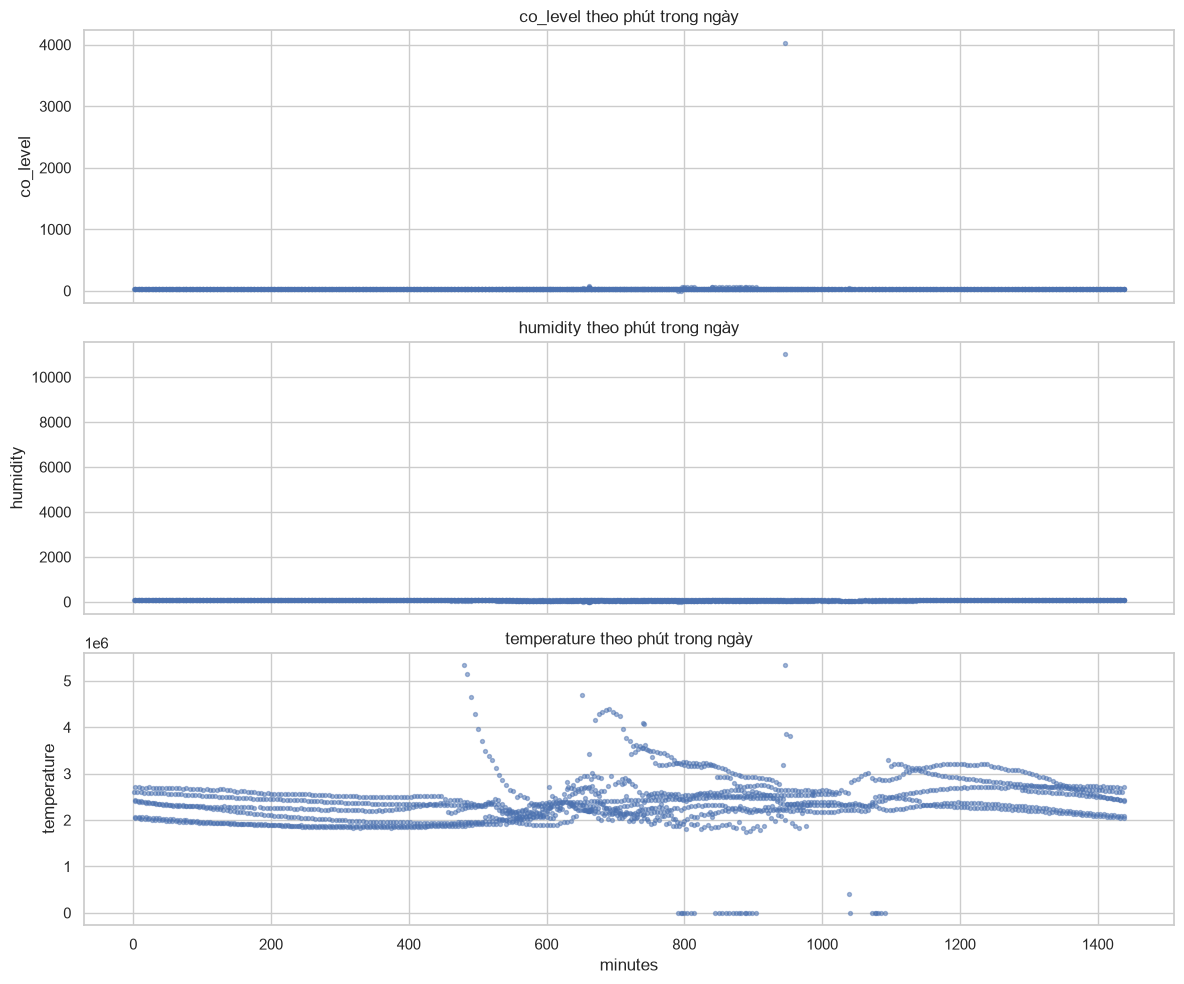

In [5]:
HO_TEN = "Ngô Thành Khôi"
MSSV = "6451071038"
print(f"{HO_TEN} - {MSSV}")
# Vẽ 3 biểu đồ scatter theo trục phút trong ngày
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, ["co_level", "humidity", "temperature"]):
    ax.scatter(df_track["minutes"], df_track[col], s=8, alpha=0.5)
    ax.set_ylabel(col)
    ax.set_title(f"{col} theo phút trong ngày")
axes[-1].set_xlabel("minutes")
plt.tight_layout()
plt.show()
